In [44]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt 
import seaborn as sns

In [19]:
data = pd.read_csv("emergency_data.csv")
print("CSV loaded successfully")
print(f"number of records: {len(data)}")

CSV loaded successfully
number of records: 10000


In [38]:
print("Dataset Shape:\n")
print(data.shape)

Dataset Shape:

(10000, 11)


In [35]:
print("First 5 rows:\n")
data.head()

First 5 rows:



,area_id,hour,day_of_week,month,population_density,traffic_level,temperature,rainfall,major_event,historical_emergencies,emergency_occurred
0,10,23,5,4,8330,39,26.73,11.67,1,22,0
1,16,3,0,12,8190,40,6.03,17.19,0,20,1
2,12,19,1,11,8662,41,22.33,10.28,1,17,0
3,41,0,1,9,7983,36,27.44,17.72,0,17,0
4,12,16,3,6,8008,43,9.21,18.72,0,18,0


In [34]:
print("Column names:\n")
for col in data:
    print(col)

Column names:

area_id
hour
day_of_week
month
population_density
traffic_level
temperature
rainfall
major_event
historical_emergencies
emergency_occurred


In [33]:
print("Unique Values of each Column: \n")
for col in data:
    print(col, data[col].unique())

Unique Values of each Column: 

area_id [10 16 12 41 23  8 15  6  3 48 34 26 13 42 36 21 46 24 19 33 28 49 20 38
 30 14 45  4 37 50  1 22 11  5 25 47 18 44 35 32 17  7  9 31 40 27 39  2
 29 43]
hour [23  3 19  0 16 13 10 15 18  7 21 17  5  8  1 11 20  6  9 12 14 22  2  4]
day_of_week [5 0 1 3 6 4 2]
month [ 4 12 11  9  6  5  3 10  2  1  8  7]
population_density [ 8330  8190  8662 ... 11062 10033  7995]
traffic_level [ 39  40  41  36  43  35  53  52  88   1  34  47  56  77  16  48  51  45
  49  42  86  33  32  50  57  13  46  44  94  37  17  58  54  38  85  97
  65  55   8  91  93  61  25   7  15  11  95  82  20  83  92  90  18  84
   4  12  63  60  28  26  99  31  21  81  87   5   9  19  27  59  22  89
  30  14   2  10  96  23  29   3  79   6  72  64  62  67  24   0  98  78
 100  80  76  71  73  69  75  74  66]
temperature [26.73  6.03 22.33 ...  9.02 23.89  1.46]
rainfall [11.67 17.19 10.28 ...  7.5  19.55 12.68]
major_event [1 0]
historical_emergencies [22 20 17 18 24 19 23 26 42  4 

In [40]:
print("Data Types:\n")
print(data.dtypes)

Data Types:

area_id                     int64
hour                        int64
day_of_week                 int64
month                       int64
population_density          int64
traffic_level               int64
temperature               float64
rainfall                  float64
major_event                 int64
historical_emergencies      int64
emergency_occurred          int64
dtype: object


In [41]:
print("Missing Values:\n")
print(data.isnull().sum())

Missing Values:

area_id                   0
hour                      0
day_of_week               0
month                     0
population_density        0
traffic_level             0
temperature               0
rainfall                  0
major_event               0
historical_emergencies    0
emergency_occurred        0
dtype: int64


In [56]:
print("Statistical Summary:\n")
print(data.describe(include="all")) 

Statistical Summary:

            area_id          hour   day_of_week         month  \
count  10000.000000  10000.000000  10000.000000  10000.000000   
mean      25.620400     11.666900      2.982100      6.568800   
std       14.343489      6.911695      2.007083      3.433023   
min        1.000000      0.000000      0.000000      1.000000   
25%       13.000000      6.000000      1.000000      4.000000   
50%       26.000000     12.000000      3.000000      7.000000   
75%       38.000000     18.000000      5.000000     10.000000   
max       50.000000     23.000000      6.000000     12.000000   

       population_density  traffic_level   temperature      rainfall  \
count        10000.000000   10000.000000  10000.000000  10000.000000   
mean          9664.671500      46.467200     17.562235     10.124537   
std           3775.447144      17.754702     10.098052      5.774482   
min            500.000000       0.000000      0.000000      0.000000   
25%           8230.000000      3

In [24]:
x = data.drop("emergency_occurred", axis=1)
y = data["emergency_occurred"]

x_train, x_test, y_train, y_test = train_test_split(x, y, 
                                                    test_size = 0.2, 
                                                    random_state = 42, 
                                                    stratify = y)

In [25]:
model = RandomForestClassifier(n_estimators = 200,
                               max_depth = 12,
                               random_state = 42,
                               class_weight = 'balanced')
model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 

In [43]:
probabilities = model.predict_proba(x_test)[:, 1]
results = x_test.copy()
results["probability"] = probabilities * 100
area_risk = dict(results.groupby('area_id')['probability'].mean().sort_values(ascending=False))

for i in area_risk:
    print(f"Area ID: {i}, Probability: {area_risk[i]}%")

Area ID: 27, Probability: 92.70123684861566%
Area ID: 3, Probability: 92.43192960259961%
Area ID: 18, Probability: 92.1186776037976%
Area ID: 11, Probability: 91.62283196995267%
Area ID: 42, Probability: 90.71645881539017%
Area ID: 17, Probability: 58.262354353657955%
Area ID: 8, Probability: 57.5270733375006%
Area ID: 29, Probability: 56.90243055127291%
Area ID: 30, Probability: 56.186922138845794%
Area ID: 32, Probability: 55.99658483413668%
Area ID: 6, Probability: 54.785950632687296%
Area ID: 25, Probability: 54.64284638178924%
Area ID: 40, Probability: 53.97351292475424%
Area ID: 39, Probability: 53.22688993175514%
Area ID: 22, Probability: 52.83583705552948%
Area ID: 15, Probability: 52.500677292184875%
Area ID: 24, Probability: 51.86814860992625%
Area ID: 49, Probability: 51.32066921948233%
Area ID: 45, Probability: 51.25882442452034%
Area ID: 1, Probability: 50.93623143168164%
Area ID: 4, Probability: 50.66467398072318%
Area ID: 19, Probability: 50.56257404855085%
Area ID: 21, 

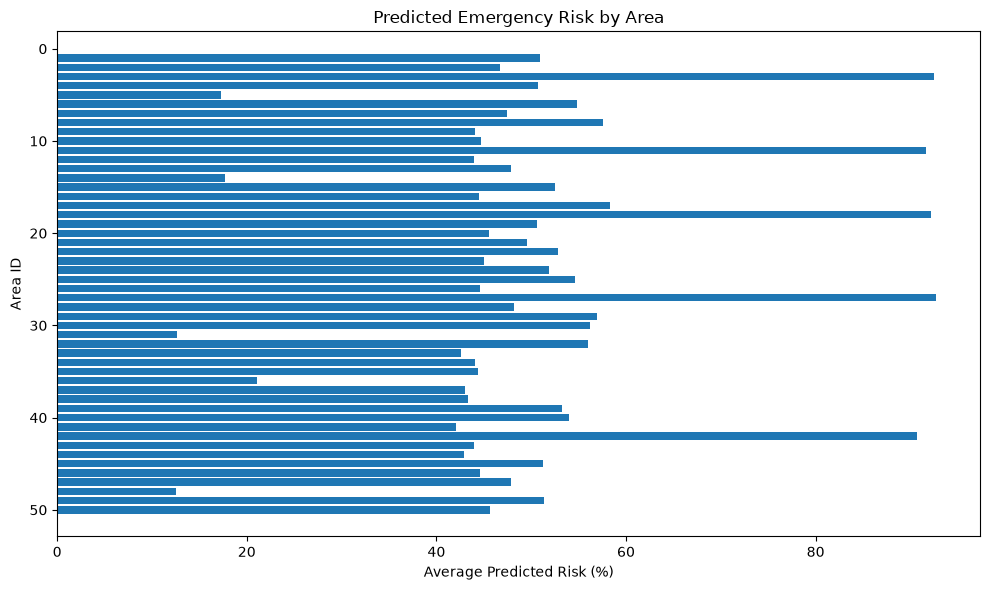

In [48]:
plt.figure(figsize=(10, 6))

plt.barh(
    list(area_risk.keys()),
    list(area_risk.values()))

plt.title("Predicted Emergency Risk by Area")
plt.xlabel("Average Predicted Risk (%)")
plt.ylabel("Area ID")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

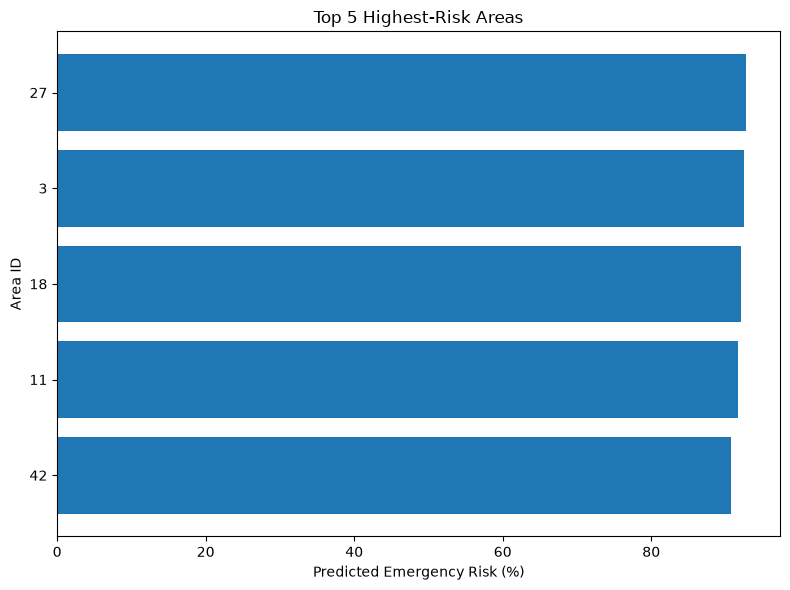

In [54]:
top_5 = dict(list(area_risk.items())[:5])

plt.figure(figsize=(8, 6))

plt.barh(
    [str(area) for area in top_5.keys()],
    list(top_5.values()))

plt.title("Top 5 Highest-Risk Areas")
plt.xlabel("Predicted Emergency Risk (%)")
plt.ylabel("Area ID")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [31]:
f = open("output_data.txt", 'w')
for i in area_risk:
    x = f"Area ID: {i}, Probability: {area_risk[i]}% \n"
    f.write(x)
f.close()
    